# AP 155 Lab Exercise
---
## Exercise 8: Root Finding

_Instructions_: 
- **Report figure:**
    - Solve $m$ using Eq. (2) with any of your root finding function; then plot the magnetization $m(t)$ vs $t$. Use $t\in[0.001,2.0]$.
- **Report discussion:**
    - Explain the report figure.
    - For each root-finding methods (relaxation, bisection, newton, secant), give an advantage and disadvantage.
- **Code**: Complete the code and ensure it is functional, error-free, readable, and efficient (where needed). Include concise Markdown documentation highlighting the critical steps of your algorithm for each problem.

### Student Information
- _Full Name (Last Name, First Name)_: Baculo, Ezira Lojelle 
- _Student No._: 2024-11845
- _Section_: THR-TX-3

### Grading Information (c/o Lab Instructor)
- [Rubrics description link](https://drive.google.com/file/d/1BMSlPot2Mc7XLu0eo4S8I8gLBsIadbCL/view?usp=sharing) (Note: percentages may still be tweaked)

| Criteria | Score | Subtotal |
| --- | --- | --- |
| Report figure | XX | 20 |
| Report discussion | XX | 20|
| Code readability | XX | 20 |
| Code efficiency | XX | 20 | 
| Code appropriateness  | XX | 20 | 
| **TOTAL** | XXX | 100 |

_Date and Time Scored (MM/DD/YYYY HH:MM AM/PM):_:_

---
## Section 1: Report

### Report figure

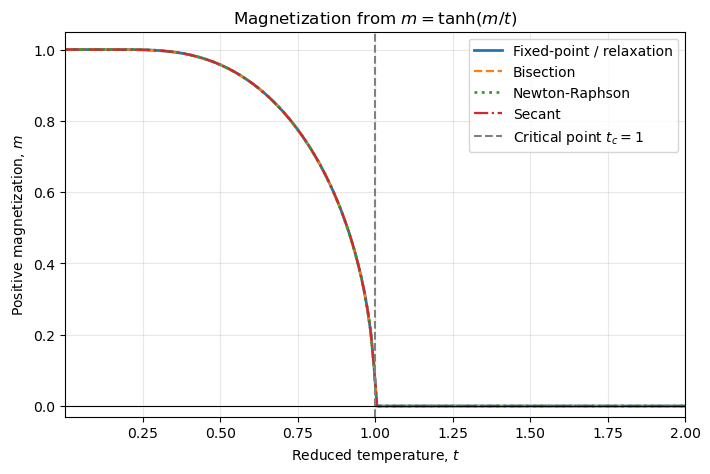

In [96]:
fig1

**Figure 1.** Positive solution of the mean-field equation $m=\tanh(m/t)$ over $t\in[0.001,2.0]$. The nonzero magnetization diminishes as the temperature nears the critical value $t=1$ and reaches zero beyond it. The four numerical techniques follow the same positive path and coincide at the plot scale.

### Report discussion

(1) The equation consistently has the solution $m=0$. For $t<1$, it also has nonzero solutions; this figure follows the positive branch. As $t$ approaches $1$ from the left, the positive solution approaches zero. For $t\geq1$, the only physical solution on this branch is $m=0$.
\
\
(2) The three roots are approximately $x=-1.192685765$, $x=2$, and $x=4.595863565$. In fact, $f(x)=(x-2)^2(e^x-x^3-2)$, so $x=2$ is a double root and does not change the sign of $f$.

| Method | Advantage | Disadvantage |
|---|---|---|
| *Fixed-point (relaxation)* | Simple; needs only a fixed-point map. | Converges only for suitable maps and starting values; here convergence near $x=2$ is very slow because $|g' (2)|=1$. |
| *Bisection* | Reliable when a continuous function alters its sign throughout the interval. | Needs a valid bracket; typically overlooks the double root at $x=2$ because there is no sign change. |
| *Newton-Raphson* | Extremely fast near a simple root when the derivative can be applied. | Needs the derivative; may fail if the derivative is zero or the starting guess is bad. |
| *Secant* | Does not require an explicit derivative and is usually fast. | Dependent on initial guesses and may converge to an alternative root or fail. |

### Other comments
- Nababaliw na po ako WHAHAHAHA. Sana kaya pa. Applied Physics 155 is my descent to madness.
- God bless na lang.
- 🫂🫂🫂

#### Disclosure of AI Use:

I acknowledge the use of Gemini (accessed October 2026) to generate a first draft of the algorithms. All AI-assisted suggestions were reviewed and revised with the help of the references provided in the lecture and researched to ensure accuracy and clarity of meaning.

---
## Section 2: Code

In [80]:
import numpy as np
import matplotlib.pyplot as plt
import math

### Problem: Root Finding

Implement root finders *manually* to find the roots of an arbitrary function

**(a)** 
- Consider the nonlinear function
$$
f(x) = -x^5 + 4x^4 - 4x^3 + x^2 e^x - 2x^2 -4xe^x + 8x + 4e^x -8 \tag{1}
$$
- Plot the function from $x=-2$ to $x=5$. You may want to "enlarge" the plot by cropping the $y$-axis. You should be able to estimate where the roots are approximately
- From (b) to (e), you will manually write functions to get the roots of Eq. $(1)$.
- You should have 3 roots. Check to see which method have trouble calculating some roots.

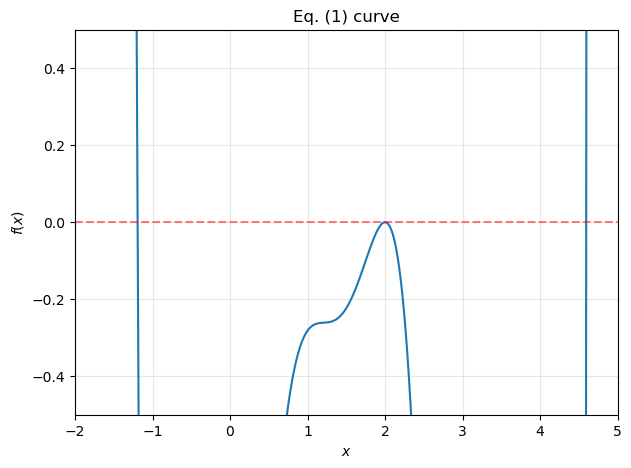

In [81]:
def the_func(x):
    return (-x**5) + (4*x**4) - (4*x**3) + ((x**2)*np.exp(x)) - \
            (2*x**2) - (4*x*np.exp(x)) + (8*x) + (4*np.exp(x)) - 8

def g(x):
    return (the_func(x) - 8*x)/(-8)

def the_funcPrime(x):
    return (-5*x**4 + 16*x**3 - 12*x**2 - 4*x + 8 + np.exp(x)*(x**2 - 2*x))

xlist = np.linspace(-2, 5, 1000)
fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(xlist, the_func(xlist), label=r"$f(x)$")
ax.grid(alpha=0.3)
ax.set(xlabel=r'$x$', ylabel=r'$f(x)$', title='Eq. (1) curve', xlim=(-2, 5), ylim=(-0.5, 0.5))
ax.axhline(0, c='r', alpha=0.5, ls='--')
plt.show()

**(b) Fixed-point method (i.e. relaxation method)**
- create a function that solves the roots $x^*$ of a given function $g$ from $x=g(x)$ using fixed-point method
- input: function, initial guess, max iterations, tolerance (you may use tolerance $\epsilon=10^{-8}$)
- output: root
- it's possible you might not get some roots, why?

In [82]:
def root_relaxation(g_function, x0, max_iters=1000, tol=1e-8):
    """
    Finds the root of x = g(x) using the fixed-point (relaxation) method.
    """
    x_prev = x0
    for i in range(max_iters):
        x_curr = g_function(x_prev)
        
        # Check for convergence (handling division by zero for x_curr near 0)
        if x_curr != 0:
            relative_error = abs(x_curr - x_prev) / abs(x_curr)
        else:
            relative_error = abs(x_curr - x_prev)
            
        if relative_error <= tol:
            return x_curr
            
        x_prev = x_curr
        
    print(f"Relaxation method did not converge in {max_iters} iterations.")
    return x_prev

**(c) Bisection method**
- create a function `root_bisection()` that solves the roots $x^*$ of a given function $f$ using bisection method
- input: function, two initial guesses bracketing root, max iterations, tolerance (you may use tolerance $\epsilon=10^{-8}$)
- output: root
- it's possible you might not get some roots, why?

In [87]:
# Turn into float

def root_bisection(input_function, x0: float, x1: float, max_iters: int = 200, tol: float = 1e-8):
    # Find a root using bisection on a sign-changing interval
    if max_iters < 1 or tol <= 0 or x0 == x1:
        raise ValueError("Invalid parameters: max_iters >= 1, tol > 0, and x0 != x1.")

    a, b = sorted((float(x0), float(x1)))
    f_a, f_b = float(input_function(a)), float(input_function(b))

    if not (np.isfinite(f_a) and np.isfinite(f_b)):
        raise ValueError("Endpoint function values must be finite.")
    if f_a == 0.0: return a
    if f_b == 0.0: return b
    if np.signbit(f_a) == np.signbit(f_b):
        raise ValueError("Endpoints must bracket a sign change.")

    for _ in range(max_iters):
        midpoint = (a + b) / 2.0
        f_mid = float(input_function(midpoint))

        if not np.isfinite(f_mid):
            raise RuntimeError("Non-finite function value encountered.")
        if f_mid == 0.0 or (b - a) / 2.0 <= tol * max(1.0, abs(midpoint)):
            return midpoint

        if np.signbit(f_mid) == np.signbit(f_a):
            a, f_a = midpoint, f_mid
        else:
            b, f_b = midpoint, f_mid

    raise RuntimeError(f"Bisection method did not converge in {max_iters} iterations.")

**(d) Newton's method (i.e. Newton-Raphson method)**
- create a function `root_newton()` that solves the roots $x^*$ of a given function $f$ and $f'$ using newton's method
- input: function, first derivative of the function, initial guess, max iterations, tolerance (you may use tolerance $\epsilon=10^{-8}$)
- output: root
- it's possible you might not get some roots, why?

In [84]:
def root_newton(input_function, input_derivative, x0, max_iters=1000, tol=1e-8):
    """
    Finds the root of input_function(x) = 0 using the Newton-Raphson method.
    """
    x_prev = x0
    for i in range(max_iters):
        df = input_derivative(x_prev)
        if df == 0:
            print("Warning: Derivative is zero. Newton's method failed.")
            return x_prev
            
        x_curr = x_prev - input_function(x_prev) / df
        
        # Check for convergence
        if x_curr != 0:
            relative_error = abs(x_curr - x_prev) / abs(x_curr)
        else:
            relative_error = abs(x_curr - x_prev)
            
        if relative_error <= tol:
            return x_curr
            
        x_prev = x_curr
        
    print(f"Newton's method did not converge in {max_iters} iterations.")
    return x_prev

**(e) Secant method**
- create a function `root_secant()` that solves the roots $x^*$ of a given function $f$ using secant method
- input: function, two initial guesses (doesn't need to bracket the root), max iterations, tolerance (you may use tolerance $\epsilon=10^{-8}$)
- output: root
- it's possible you might not get some roots, why?

In [85]:
def root_secant(input_function, x0, x1, max_iters=1000, tol=1e-8):
    """
    Finds the root of input_function(x) = 0 using the secant method.
    """
    f0 = input_function(x0)
    f1 = input_function(x1)
    
    for i in range(max_iters):
        if f1 - f0 == 0:
            print("Warning: Division by zero in secant method due to equal function values.")
            return x1
            
        # Secant update formula
        x_next = x1 - f1 * (x1 - x0) / (f1 - f0)
        
        # Check for convergence
        if x_next != 0:
            relative_error = abs(x_next - x1) / abs(x_next)
        else:
            relative_error = abs(x_next - x1)
            
        if relative_error <= tol:
            return x_next
            
        x0, f0 = x1, f1
        x1 = x_next
        f1 = input_function(x_next)
        
    print(f"Secant method did not converge in {max_iters} iterations.")
    return x1

**(f) [Report figure]** (From Landau2015, p.148). 
- Consider the following transcendental equation:
  $$ m = \tanh\left(\frac{m}{t} \right). \tag{2}$$
- Solve $m$ using Eq. (2) with all of your root finding functions; then plot the magnetization $m(t)$ vs $t$. Use $t\in[0.001,2.0]$.
- You may use `np.tanh()`, in case of Newton-solver, there is no `np.sech()` so you have to use the identity $\cosh(x)=\frac{1}{\text{sech}(x)}$
- Hint: you have to recast the equation as a lambda function (taking only input $m$ with $t$ specified)
- Generate a plot showing $m(t)$ as a function of $t$.

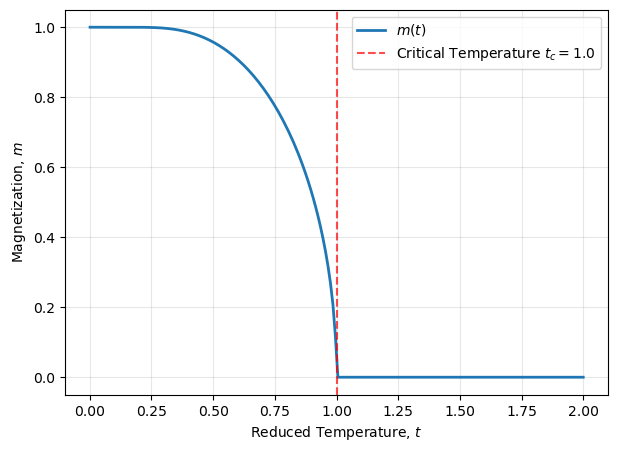

In [94]:
# Initial try:

tlist = np.linspace(0.001, 2.0, 200)
roots_pos = []

for t in tlist:
    if t < 1.0:
        # Define f(m) = m - tanh(m/t)
        f = lambda m: m - np.tanh(m / t)
        # For t < 1, a positive root exists in (0, 1] 
        # We use a small lower bound near 0 to avoid converging to the trivial root 0
        root = root_bisection(f, 1e-5, 1.0)
        roots_pos.append(root)
    else:
        # For t >= 1, the only real root is the trivial root m = 0
        roots_pos.append(0.0)

# Plot the magnetization curve m(t) vs t
fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(tlist, roots_pos, label=r'$m(t)$', linewidth=2)
ax.axvline(1.0, color='red', linestyle='--', alpha=0.7, label='Critical Temperature $t_c=1.0$')
ax.grid(alpha=0.3)
ax.set_xlabel(r'Reduced Temperature, $t$')
ax.set_ylabel(r'Magnetization, $m$')
ax.legend()

plt.show()

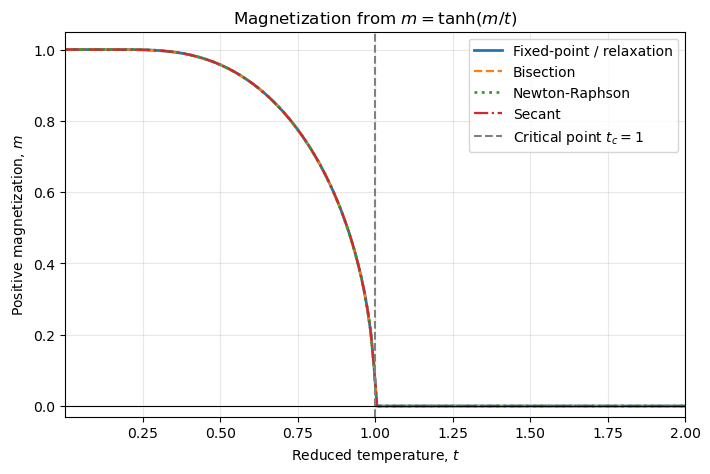

Maximum spread among the four methods over the temperature grid: 1.27e-07


In [97]:
# Now, using all methods:

tlist = np.linspace(0.001, 2.0, 200)
tol = 1e-8
roots_relaxation = []
roots_bisection = []
roots_newton = []
roots_secant = []

for t in tlist:
    # Bind t as a default argument so each callable uses the current temperature
    f_m = lambda m, t=t: m - np.tanh(m / t)
    f_m_prime = lambda m, t=t: 1.0 - (1.0 - np.tanh(m / t) ** 2) / t
    g_m = lambda m, t=t: np.tanh(m / t)

    if t < 1.0:
        # Seek the positive nonzero branch below the critical temperature
        roots_relaxation.append(root_relaxation(g_m, 0.9, max_iters=50_000, tol=tol))
        roots_bisection.append(root_bisection(f_m, 1e-8, 1.0, max_iters=200, tol=tol))
        roots_newton.append(root_newton(f_m, f_m_prime, 0.9, max_iters=1_000, tol=tol))
        roots_secant.append(root_secant(f_m, 0.3, 1.0, max_iters=1_000, tol=tol))
    else:
        # For t >= 1, m = 0 is the only nonnegative solution
        roots_relaxation.append(root_relaxation(g_m, 0.0, max_iters=100, tol=tol))
        roots_bisection.append(root_bisection(f_m, 0.0, 1.0, max_iters=200, tol=tol))
        roots_newton.append(root_newton(f_m, f_m_prime, 0.0, max_iters=100, tol=tol))
        roots_secant.append(root_secant(f_m, -0.1, 0.1, max_iters=100, tol=tol))

# Plot all the graphs; Final figure
fig1, ax = plt.subplots(figsize=(8, 5))
ax.plot(tlist, roots_relaxation, label="Fixed-point / relaxation", linewidth=2)
ax.plot(tlist, roots_bisection, "--", label="Bisection", linewidth=1.6)
ax.plot(tlist, roots_newton, ":", label="Newton-Raphson", linewidth=2)
ax.plot(tlist, roots_secant, "-.", label="Secant", linewidth=1.6)
ax.axvline(1.0, color="gray", linestyle="--", linewidth=1.5, label=r"Critical point $t_c=1$")
ax.axhline(0.0, color="black", linewidth=0.8)
ax.set(
    xlabel=r"Reduced temperature, $t$",
    ylabel=r"Positive magnetization, $m$",
    title=r"Magnetization from $m=\tanh(m/t)$",
    xlim=(0.001, 2.0),
    ylim=(-0.03, 1.05)
)
ax.grid(alpha=0.3)
ax.legend()
fig.tight_layout()
plt.show()

# This is the maximum discrepancy
method_values = np.vstack((roots_relaxation, roots_bisection, roots_newton, roots_secant))
max_spread = np.max(np.ptp(method_values, axis=0))
print(f"Maximum spread among the four methods over the temperature grid: {max_spread:.2e}")

#### Problem code summary

The script solves the transcendental magnetization equation $m = \tanh(m/t)$ by utilizing four distinct numerical root-finding methods to evaluate the performance and spontaneous symmetry breaking of the system across a wide temperature range. To prevent convergence to the zero solution below the critical temperature $t_c = 1$, the initial boundaries and guesses were set up for the relaxation, bisection, Newton-Raphson, and secant methods to focus on the positive magnetization branch. By structuring the loops to bind the temperature value within local lambda expressions, the code was streamlined and mathematical consistency was preserved across all methods. Ultimately, the close alignment of the curves with a maximum deviation around $10^{-7}$ confirms the strong execution and accuracy of each custom-built root finder. 


---
## Section 3: Notes

### Convergence criteria

$$\frac{|x^{(k)} - x^{(k-1)}|}{x^{(k)}} \leq \epsilon, $$ where $x^{k}$ is the $k$-th guess and $\epsilon$ is a chosen tolerance. Example value is $\epsilon=10^{-8}.$

### Fixed-point iteration

$$ x=g(x) $$

example: solving $e^{x-\sqrt{x}}-x=0$... we can rewrite this as $x=e^{x-\sqrt{x}}.$ Then, $g(x)=e^{x-\sqrt{x}}$.

#### Algorithm:

$$ x^{(k)} = g(x^{(k-1)})$$
- start with initial estimate $x^{(0)}$
- solve with $x^{(0)}$, we get $x^{(1)}$ then plug this $x^{(1)}$ back to RHS... until we reach $x^{(k)}$ where $x^{(k)}$

### Bisection

Given 
$$ f(x) =0 $$

example: solving $e^{x-\sqrt{x}}-x=0$... Then, $f(x)=e^{x-\sqrt{x}} - x$.

#### Algorithm:

- Take the interval $(x_0,x_1)$ (for which we know $f(x_0)f(x_1)<0$) and evaluate the midpoint:
$$ x_2 = \frac{x_0 + x_1}{2}$$ 
- At this point, we will halve the original interval $(x_0,x_1)$, thereby explaining why this approach is also known as the internal halving method. Thus, we are producing two subintervals: $(x_0,x_2)$ and $(x_2,x_1)$. The sign of $f(x_2)$ will determine in which of these two subintervals the root lies.
- If $f(x_0)f(x_2)<0$, then the root is in $(x_0,x_2)$. Thus, we could rename $x1 \leftarrow x2$ and repeat the entire process (which started with an $x_0$ and an $x_1$ that bracket the root).
- If, on the other hand, $f(x_0)f(x_2)>0$, then the root is in $(x_2,x_1)$. Thus, we could rename $x_0\leftarrow x_2$ and repeat the entire process.
- There is also the extreme scenario where $f(x_0)f(x_2)= 0$ but, since we are dealing with floating-point numbers this is unlikely. Even so, if it does happen, it’s merely informing you that you’ve already found the root.

### Newton's method

Given 
$$ f(x) =0 $$
and
we know
$$ f'(x) $$

example: solving $e^{x-\sqrt{x}}-x=0$... Then, $f(x)=e^{x-\sqrt{x}} - x$ and $f'(x)=e^{x-\sqrt{x}}(1-0.5x^{-0.5}) - 1$.

#### Algorithm:
- Start with a guess $x^{(0)}$ and solve the next iteration with
$$ x^{(k)} = x^{(k-1)} - \frac{f(x^{(k-1)})}{f'(x^{(k-1)})}$$
- plug in solved $x^{(k)}$ as new input $x^{(k-1)}$
- Iterate until tolerance is reached

### Secant method

Given 
$$ f(x) =0 $$

example: solving $e^{x-\sqrt{x}}-x=0$... Then, $f(x)=e^{x-\sqrt{x}} - x$.

#### Algorithm:
- Start with a guess $x^{(0)}$ and $x^{(1)}$ (does not have to bracket the root) and solve the next iteration with
$$ x^{(k)} = x^{(k-1)} - f(x^{(k-1)})  \frac{x^{(k-1)}-x^{(k-2)}}{f(x^{(k-1)})-f(x^{(k-2)})}$$
- Iterate until tolerance is reached